# Theory figures: linear models and frozen random features
The combined M6 figure compares random readout initialization in both models.
Run setup, the core model, and both simulation cells before the M6 plotting cell.
Then rerun plotting cells without training.
The coefficient, log–log, and digits checks are optional.


In [1]:
import numpy as np, matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import os

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
FIG = {
    "theory": "M_linear_theory",  # main text
    "init": "A_init_sweep",  # appendix
    "rf": "A_random_features",
}  # appendix
FAST = False  # True: fewer seeds, quick look

ORDER = ["x", "eps", "v"]  # always x, ε, v
COL = {"x": "#d62728", "eps": "#1f77b4", "v": "#2ca02c"}  # x red, ε blue, v green
LAB = {"x": r"$x$", "eps": r"$\epsilon$", "v": r"$v$"}

plt.rcParams.update(
    {
        "font.size": 7,
        "axes.labelsize": 7,
        "legend.fontsize": 6,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "axes.linewidth": 0.6,
        "lines.linewidth": 1.1,
    }
)


def save(fig, key):
    for ext in ("pdf", "png"):
        fig.savefig(
            f"{OUT}/{FIG[key]}.{ext}", bbox_inches="tight", pad_inches=0.02, dpi=250
        )

## Core model
Linear path $z_t = t x + (1-t)\varepsilon$, linear predictor $B_q z_t$, native targets $y_x=x$, $y_\epsilon=\varepsilon$, $y_v=x-\varepsilon$.
Gradient flow on the native loss, decoded to velocity $A_q$: $\dot A_q = V_v^\top - A_q U$ (Prop. 1).
`Sigma` is the population second-moment matrix (identity for $\mathcal N(0,I)$; any data otherwise).

In [2]:
def moments(X, t, Sigma=None):
    """Empirical (U, Vv) and population (C, VP) velocity moments at flow time t."""
    n, d = X.shape
    I = np.eye(d)
    Sigma = I if Sigma is None else Sigma
    S = X.T @ X / n
    U = t * t * S + (1 - t) ** 2 * I
    C = t * t * Sigma + (1 - t) ** 2 * I
    Vv = t * S - (1 - t) * I
    VP = t * Sigma - (1 - t) * I
    return S, U, C, Vv, VP


def A0(q, d, t):
    """Decoded initial velocity map under native zero init B_q(0)=0."""
    I = np.eye(d)
    return {"x": -I / (1 - t), "eps": I / t, "v": 0 * I}[q]


def A_of(A0_, U, Vv, tau):
    """Exact solution A(τ) = A0 e^{-τU} + V_v^T U^{-1}(I - e^{-τU})."""
    lam, Q = np.linalg.eigh(U)
    e = np.exp(-lam * tau)
    g = (1 - e) / lam
    return A0_ @ (Q * e) @ Q.T + Vv.T @ (Q * g) @ Q.T


def G(A, U, C, Vv, VP, d):
    """Population minus training velocity risk, up to an A-independent constant."""
    return (np.trace(A @ (C - U) @ A.T) - 2 * np.trace(A @ (VP - Vv))) / d


def deltaG(q, X, t, taus, Sigma=None):
    """ΔG_q(τ) = G(A_q(τ)) - G(A_q(0)) along exact gradient flow."""
    n, d = X.shape
    S, U, C, Vv, VP = moments(X, t, Sigma)
    a0 = A0(q, d, t)
    g0 = G(a0, U, C, Vv, VP, d)
    return np.array(
        [G(A_of(a0, U, Vv, tau), U, C, Vv, VP, d) - g0 for tau in np.atleast_1d(taus)]
    )


def kappa_of(Sigma, m4, n, d):
    """κ = (E||x||^4 - tr Σ^2)/(nd); equals (d+1)/n for N(0, I_d)."""
    return (m4 - np.trace(Sigma @ Sigma)) / (n * d)


def pred_linear(q, t, kappa):
    """Expected early-time coefficients of Prop. 2."""
    return {"x": 2 * t * t / (1 - t) ** 2 * kappa, "v": 2 * t * t * kappa, "eps": 0.0}[
        q
    ]


def pred_cubic_eps(t, kappa):
    return t * t * (1 - t) ** 2 * kappa


# native-space conversions, used to decode SGD iterates
def conv(q, B, t):
    d = B.shape[0]
    I = np.eye(d)
    return {"x": (B - I) / (1 - t), "eps": (I - B) / t, "v": B}[q]


def sgd_linear(q, X, t, B0, eta, K, record_k, rng, Sigma=None):
    """Fresh-noise SGD on the native loss; returns ΔG at the recorded steps (τ = k·η·2/d)."""
    n, d = X.shape
    S, U, C, Vv, VP = moments(X, t, Sigma)
    B = B0.copy()
    g0 = G(conv(q, B, t), U, C, Vv, VP, d)
    out = []
    for k in range(1, K + 1):
        E = rng.standard_normal((n, d))
        Z = t * X + (1 - t) * E
        Y = {"x": X, "eps": E, "v": X - E}[q]
        B -= eta * (2 / d) * (B @ (Z.T @ Z / n) - Y.T @ Z / n)
        if k in record_k:
            out.append(G(conv(q, B, t), U, C, Vv, VP, d) - g0)
    return np.array(out)

## Numerical check of Prop. 2 (Gaussian data, several $t$)
Linear coefficients for $x$ and $v$, the vanishing linear term for $\epsilon$, and the cubic $\epsilon$ term
(the per-dataset $\tau^2$ term $\propto \mathrm{tr}(\Sigma - S)$ has zero mean; it is removed before reading the cubic).

In [3]:
d, n = 32, 128
kap = (d + 1) / n
nsets = 200 if FAST else 400
for t in [0.3, 0.5, 0.7]:
    tau = 1e-3
    acc = {q: [] for q in ORDER}
    cub = []
    for s in range(nsets):
        X = np.random.default_rng(s).standard_normal((n, d))
        for q in ORDER:
            acc[q].append(deltaG(q, X, t, tau)[0])
        taus = np.array([2e-3, 4e-3])
        S = X.T @ X / n
        trM = d - np.trace(S)
        c = (1 - t) / t
        cub.append(
            (deltaG("eps", X, t, taus) - (t * t / d) * c * c * taus**2 * trM) / taus**3
        )
    print(
        f"t={t}: "
        + " | ".join(
            f"E[dG_{q}]/tau={np.mean(acc[q]) / tau:.4f} (pred {pred_linear(q, t, kap):.4f})"
            for q in ORDER
        )
        + f" | eps cubic {np.mean(cub, 0).round(4)} (pred {pred_cubic_eps(t, kap):.4f})"
    )

t=0.3: E[dG_x]/tau=0.0942 (pred 0.0947) | E[dG_eps]/tau=0.0000 (pred 0.0000) | E[dG_v]/tau=0.0467 (pred 0.0464) | eps cubic [0.011 0.011] (pred 0.0114)
t=0.5: E[dG_x]/tau=0.5127 (pred 0.5156) | E[dG_eps]/tau=0.0000 (pred 0.0000) | E[dG_v]/tau=0.1289 (pred 0.1289) | eps cubic [0.0159 0.0159] (pred 0.0161)
t=0.7: E[dG_x]/tau=2.7901 (pred 2.8073) | E[dG_eps]/tau=0.0000 (pred 0.0000) | E[dG_v]/tau=0.2517 (pred 0.2527) | eps cubic [0.0113 0.0113] (pred 0.0114)


## Main figure: exact gradient flow vs fresh-noise SGD, dataset-averaged ($t=1/2$)

x: tau at half of final gap = 0.336; final gap 0.2731; peak 0.3427
eps: tau at half of final gap = 4.413; final gap 0.2720; peak 0.2720
v: tau at half of final gap = 1.670; final gap 0.2723; peak 0.2723


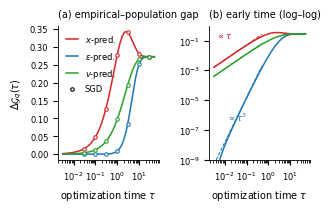

In [4]:
d, n, t = 32, 128, 0.5
taus = np.logspace(-2.5, 1.7, 200)
n_sets = 20 if FAST else 50
exact = {q: np.zeros_like(taus) for q in ORDER}
for s in range(n_sets):
    X = np.random.default_rng(s).standard_normal((n, d))
    for q in ORDER:
        exact[q] += deltaG(q, X, t, taus) / n_sets

eta = 0.16
dtau = eta * 2 / d
mark_taus = np.array([0.03, 0.1, 0.3, 1, 3, 10, 30])
mark_k = np.round(mark_taus / dtau).astype(int)
sgd = {q: np.zeros(len(mark_taus)) for q in ORDER}
for s in range(n_sets):
    X = np.random.default_rng(s).standard_normal((n, d))
    for q in ORDER:
        sgd[q] += (
            sgd_linear(
                q,
                X,
                t,
                np.zeros((d, d)),
                eta,
                mark_k.max(),
                set(mark_k),
                np.random.default_rng(1000 + s),
            )
            / n_sets
        )

plateau = exact["v"][-1]
for q in ORDER:
    print(
        f"{q}: tau at half of final gap = {taus[np.argmax(exact[q] >= 0.5 * plateau)]:.3f}; final gap {exact[q][-1]:.4f}; peak {exact[q].max():.4f}"
    )

fig, ax = plt.subplots(1, 2, figsize=(3.25, 1.75), gridspec_kw=dict(wspace=0.5))
for q in ORDER:
    ax[0].plot(taus, exact[q], color=COL[q], label=f"{LAB[q]}-pred.")
    ax[0].plot(mark_taus, sgd[q], "o", ms=2.5, mfc="white", mew=0.8, color=COL[q])
    ax[1].plot(taus, exact[q], color=COL[q])
ax[0].plot([], [], "o", ms=2.5, mfc="white", mew=0.8, color="k", label="SGD")
ax[0].legend(frameon=False, loc="upper left", handlelength=1.5)
ax[0].set_xscale("log")
ax[0].set_xlabel(r"optimization time $\tau$")
ax[0].set_ylabel(r"$\Delta\mathcal{G}_q(\tau)$")
tt = np.logspace(-2.5, -0.3, 50)
for q in ORDER:
    y = pred_linear(q, t, kap) * tt if q != "eps" else pred_cubic_eps(t, kap) * tt**3
    ax[1].plot(tt, y, "--", color=COL[q], lw=0.7)
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_ylim(1e-9, 1)
ax[1].set_xlabel(r"optimization time $\tau$")
ax[1].text(0.004, 1.5e-1, r"$\propto\tau$", fontsize=6, color=COL["x"])
ax[1].text(0.012, 4e-7, r"$\propto\tau^3$", fontsize=6, color=COL["eps"])
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
ax[0].set_title("(a) empirical–population gap", fontsize=7, loc="left")
ax[1].set_title("(b) early time (log–log)", fontsize=7, loc="left")
save(fig, "theory")
plt.show()

## Linear initialization study: A_init_sweep
The three panels change the standard deviation of the initial readout entries.
The rightmost panel uses $B_{ij}(0)\sim\mathcal N(0,1/d)$.
The combined M6 figure selects this panel.


In [5]:
# Compute the linear initialization study and retain its curves.
d, n, t = 32, 128, 0.5
eta = 0.16
dtau = eta * 2 / d
K = int(30 / dtau)
ck = np.unique(np.round(np.logspace(0, np.log10(K), 40)).astype(int))
taus_ck = ck * dtau
scales = [
    (r"$\sigma=d^{-1}$", 1 / d),
    (r"$\sigma=(4d)^{-1/2}$", 0.5 / np.sqrt(d)),
    (r"$\sigma=d^{-1/2}$", 1 / np.sqrt(d)),
]
nseed = 12 if FAST else 40

res = {}
for name, sig in scales:
    for q in ORDER:
        runs = []
        for s in range(nseed):
            X = np.random.default_rng(s).standard_normal((n, d))
            B0 = sig * np.random.default_rng(20_000 + s).standard_normal((d, d))
            runs.append(
                sgd_linear(
                    q, X, t, B0, eta, K, set(ck), np.random.default_rng(10_000 + s)
                )
            )
        res[(name, q)] = np.array(runs)
    med = {q: np.median(res[(name, q)], 0) for q in ORDER}
    print(
        name,
        {
            q: f"tau_half={taus_ck[np.argmax(med[q] >= 0.5 * med[q][-1])]:.2f}"
            for q in ORDER
        },
    )

taus_ref = np.logspace(-2.5, 1.5, 150)
ref = {q: np.zeros_like(taus_ref) for q in ORDER}
for s in range(nseed):
    X = np.random.default_rng(s).standard_normal((n, d))
    for q in ORDER:
        ref[q] += deltaG(q, X, t, taus_ref) / nseed

# Keep these arrays separate from the RFN variables used below.
init_plot = {
    "tau": taus_ck.copy(),
    "runs": res,
    "scales": scales,
    "zero_tau": taus_ref.copy(),
    "zero_mean": ref,
    "d": d,
    "n": n,
    "t": t,
    "nseed": nseed,
}


$\sigma=d^{-1}$ {'x': 'tau_half=0.33', 'eps': 'tau_half=4.73', 'v': 'tau_half=1.69'}
$\sigma=(4d)^{-1/2}$ {'x': 'tau_half=0.33', 'eps': 'tau_half=4.73', 'v': 'tau_half=1.69'}
$\sigma=d^{-1/2}$ {'x': 'tau_half=0.27', 'eps': 'tau_half=4.73', 'v': 'tau_half=1.69'}


### Plot the initialization sweep
Run this cell after the linear simulation cell.


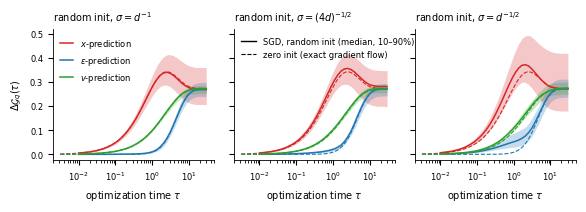

In [6]:
# Plot the three linear initialization scales without training.
fig, ax = plt.subplots(
    1, 3, figsize=(6.75, 1.7), sharey=True, gridspec_kw=dict(wspace=0.12)
)
for a, (name, sig) in zip(ax, init_plot["scales"]):
    for q in ORDER:
        # Retain the original median and 10--90% interval.
        lo, med, hi = np.percentile(init_plot["runs"][(name, q)], [10, 50, 90], axis=0)
        a.fill_between(init_plot["tau"], lo, hi, color=COL[q], alpha=0.25, lw=0)
        a.plot(
            init_plot["tau"],
            med,
            color=COL[q],
            label=f"{LAB[q]}-prediction" if a is ax[0] else None,
        )
        # The dashed reference starts from zero native outputs.
        a.plot(
            init_plot["zero_tau"], init_plot["zero_mean"][q], "--", color=COL[q], lw=0.8
        )
    a.set_xscale("log")
    a.set_xlabel(r"optimization time $\tau$")
    a.set_title(f"random init, {name}", fontsize=7, loc="left")
    a.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel(r"$\Delta\mathcal{G}_q(\tau)$")
ax[0].legend(frameon=False, handlelength=1.5, loc="upper left")
ax[1].legend(
    handles=[
        Line2D([], [], color="k", lw=1.0, label="SGD, random init (median, 10–90%)"),
        Line2D(
            [], [], color="k", lw=0.8, ls="--", label="zero init (exact gradient flow)"
        ),
    ],
    frameon=False,
    handlelength=1.8,
    loc="upper left",
)
save(fig, "init")
plt.show()

## Frozen random-feature study: A_random_features
Both panels use $phi(z)=	anh(Wz/sqrt d)$ with the same data and frozen features.
Only the readout initialization changes.
The left panel starts from $B(0)=0$.
The right panel uses $B_{ij}(0)simmathcal N(0,1/p)$.
Training can reduce the difference between these initializations.
The combined M6 figure selects the right panel.


In [7]:
# Compute the frozen-feature study and retain both initialization results.
d, n, p, t = 32, 128, 256, 0.5
nseed = 8 if FAST else 20
M_eval = 4000


def feats(Z, W):
    return np.tanh(Z @ W.T / np.sqrt(d))


def vel_rf(q, B, Z, Phi):
    return {"x": (Phi @ B.T - Z) / (1 - t), "eps": (Z - Phi @ B.T) / t, "v": Phi @ B.T}[
        q
    ]


def risks_rf(q, B, X, W, rng):
    Etr = rng.standard_normal((M_eval, d))
    Xtr = X[rng.integers(0, n, M_eval)]
    Ztr = t * Xtr + (1 - t) * Etr
    Rtr = np.mean(np.sum((vel_rf(q, B, Ztr, feats(Ztr, W)) - (Xtr - Etr)) ** 2, 1)) / d
    Xp = rng.standard_normal((M_eval, d))
    Ep = rng.standard_normal((M_eval, d))
    Zp = t * Xp + (1 - t) * Ep
    Rp = np.mean(np.sum((vel_rf(q, B, Zp, feats(Zp, W)) - (Xp - Ep)) ** 2, 1)) / d
    return Rtr, Rp


rng0 = np.random.default_rng(0)
W0 = rng0.standard_normal((p, d))
Zs = t * rng0.standard_normal((20000, d)) + (1 - t) * rng0.standard_normal((20000, d))
Ph = feats(Zs, W0)
lam_max = np.linalg.eigvalsh(Ph.T @ Ph / len(Ph)).max()
dtau = 0.3 / lam_max
eta = dtau * d / 2
K = int(40 / dtau)
ck = np.unique(np.round(np.logspace(0, np.log10(K), 30)).astype(int))
taus_ck = ck * dtau

inits = [("zero init", 0.0), (r"random init, $\sigma=p^{-1/2}$", 1 / np.sqrt(p))]
RES = {}
for iname, sig in inits:
    res = {q: [] for q in ORDER}
    for s in range(nseed):
        X = np.random.default_rng(s).standard_normal((n, d))
        W = np.random.default_rng(500 + s).standard_normal((p, d))
        rng = np.random.default_rng(1000 + s)
        B0 = sig * np.random.default_rng(2000 + s).standard_normal((d, p))
        for q in ORDER:
            B = B0.copy()
            r0 = risks_rf(q, B, X, W, np.random.default_rng(777))
            g0 = r0[1] - r0[0]
            dg = []
            for k in range(1, K + 1):
                E = rng.standard_normal((n, d))
                Z = t * X + (1 - t) * E
                Y = {"x": X, "eps": E, "v": X - E}[q]
                Phi = feats(Z, W)
                B -= eta * (2 / d) * ((B @ Phi.T - Y.T) @ Phi / n)
                if k in ck:
                    rtr, rp = risks_rf(q, B, X, W, np.random.default_rng(777))
                    dg.append(rp - rtr - g0)
            res[q].append(dg)
    RES[iname] = {q: np.array(res[q]) for q in ORDER}
    for q in ORDER:
        med = np.median(RES[iname][q], 0)
        print(
            iname,
            q,
            f"final gap {med[-1]:.3f}, tau_half {taus_ck[np.argmax(med >= 0.5 * med[-1])]:.2f}",
        )

# Retain the RFN time grid because it differs from the linear grid.
rf_plot = {
    "tau": taus_ck.copy(),
    "runs": RES,
    "inits": inits,
    "d": d,
    "n": n,
    "p": p,
    "t": t,
    "nseed": nseed,
    "M_eval": M_eval,
}


zero init x final gap 0.402, tau_half 0.16
zero init eps final gap 0.396, tau_half 1.55
zero init v final gap 0.388, tau_half 0.85
random init, $\sigma=p^{-1/2}$ x final gap 0.415, tau_half 0.16
random init, $\sigma=p^{-1/2}$ eps final gap 0.400, tau_half 1.55
random init, $\sigma=p^{-1/2}$ v final gap 0.388, tau_half 0.70


### Plot the RFN initialization comparison
Run this cell after the RFN simulation cell.


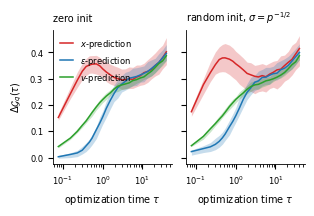

In [8]:
# Plot both RFN initializations without training.
fig, ax = plt.subplots(
    1, 2, figsize=(3.25, 1.75), sharey=True, gridspec_kw=dict(wspace=0.12)
)
for a, (iname, sig) in zip(ax, rf_plot["inits"]):
    for q in ORDER:
        # Retain the original median and 10--90% interval.
        lo, med, hi = np.percentile(rf_plot["runs"][iname][q], [10, 50, 90], 0)
        a.fill_between(rf_plot["tau"], lo, hi, color=COL[q], alpha=0.25, lw=0)
        a.plot(
            rf_plot["tau"],
            med,
            color=COL[q],
            label=f"{LAB[q]}-prediction" if a is ax[0] else None,
        )
    a.set_xscale("log")
    a.set_xlabel(r"optimization time $\tau$")
    a.spines[["top", "right"]].set_visible(False)
    a.set_title(iname, fontsize=7, loc="left")
ax[0].set_ylabel(r"$\Delta\mathcal{G}_q(\tau)$")
ax[0].legend(frameon=False, handlelength=1.5, loc="upper left")
save(fig, "rf")
plt.show()

## Combined paper figure: M6
The upper panel selects the rightmost A_init_sweep result.
The lower panel selects the random-initialization A_random_features result.
Both use initial entry variance $1/p$, with $p=d$ for linear features.
This shared rule does not match initial velocity functions or feature variances.
Solid curves show medians; shaded regions show the 10–90% intervals.
Dashed linear curves show exact zero-initialization means.
Both panels share vertical limits. Each time axis spans its own plotted time points.
The RFN study first records the gap after one update, at approximately $\tau=0.078$.
Earlier positive times have no recorded RFN values. The plot applies no time rescaling or interpolation.
The RFN panel contains SGD results, without an analytical overlay.
Run this cell after both simulation cells.
It saves `M6.pdf` and `M6.png` in `outputs/paper_figures/` without additional training.
The gap uses population minus training velocity MSE, not a generated-copying fraction.
The figure uses the shared paper fonts, light grid, and line weights.
The panels use a compact vertical layout with larger labels.
The panels have no legends. The vertical labels show only $\Delta\mathcal{G}_q(\tau)$.
Define colors and line styles in the caption: red for $x$, blue for $\epsilon$, and green for $v$.
Solid curves show random-initialization medians. Dashed curves show linear zero-initialization means. Shading shows the 10–90% intervals.
Report the initialization rule and seed counts in the caption.


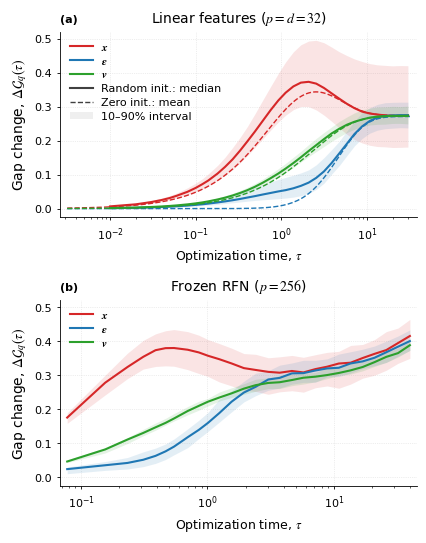

In [ ]:
# Compare linear and frozen nonlinear features under random readout initialization.
from pathlib import Path
import sys

# Find the repository from its root or a notebook subdirectory.
repo_root = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "plotting" / "paper_style.py").is_file()
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
from plotting.paper_style import RC_PARAMS

# Select the original rightmost linear panel and the random-initialization RFN panel.
linear_name = init_plot["scales"][-1][0]
rf_name = rf_plot["inits"][1][0]
FIG["combined"] = "M6"
# Save M6 beside the other main and appendix paper figures.
paper_output = repo_root / "outputs" / "paper_figures"
paper_output.mkdir(parents=True, exist_ok=True)

with plt.rc_context(RC_PARAMS):
    fig, ax = plt.subplots(2, 1, figsize=(4.2, 4.8), sharex=False, sharey=True)
    # Use compact panels and larger text for the printed figure.
    fig.subplots_adjust(left=0.19, right=0.98, bottom=0.12, top=0.93, hspace=0.58)
    for q in ORDER:
        linear_runs = init_plot["runs"][(linear_name, q)]
        rf_runs = rf_plot["runs"][rf_name][q]
        for a, tau, runs in zip(
            ax, (init_plot["tau"], rf_plot["tau"]), (linear_runs, rf_runs)
        ):
            # Summarize the retained runs without changing their values or time grids.
            lo, med, hi = np.percentile(runs, [10, 50, 90], axis=0)
            a.fill_between(tau, lo, hi, color=COL[q], alpha=0.12, linewidth=0)
            a.plot(tau, med, color=COL[q], linewidth=1.5)
        # Only the linear panel has an exact zero-initialization reference.
        ax[0].plot(
            init_plot["zero_tau"],
            init_plot["zero_mean"][q],
            color=COL[q],
            linestyle="--",
            linewidth=1.0,
        )

    titles = (
        f"Linear features ($p=d={init_plot['d']}$)",
        f"Frozen RFN ($p={rf_plot['p']}$)",
    )
    for i, (a, title) in enumerate(zip(ax, titles)):
        a.set_xscale("log")  # The vertical axis remains linear.
        # Limit each time axis to its available points, with a small edge margin.
        a.margins(x=0.02)
        a.set_xlabel(r"Optimization time, $\tau$", fontsize=12)
        a.set_ylabel(r"$\Delta\mathcal{G}_q(\tau)$", fontsize=12)
        a.set_title(title, fontsize=12, pad=8)
        a.set_title(
            f"({chr(97 + i)})", loc="left", fontsize=14, fontweight="bold", pad=7
        )
        # Use the light grid and thin axes from the current paper figures.
        a.grid(which="major", color="0.87", linewidth=0.5, linestyle=":")
        a.set_axisbelow(True)
        a.tick_params(which="major", labelsize=10.5, length=3, width=0.6)
        a.tick_params(which="minor", length=1.5, width=0.45)
        a.spines[["top", "right"]].set_visible(False)
        for spine in a.spines.values():
            spine.set_linewidth(0.6)

    for ext in ("pdf", "png"):
        fig.savefig(
            paper_output / f"{FIG['combined']}.{ext}",
            bbox_inches="tight",
            pad_inches=0.02,
            dpi=250,
        )
    plt.show()


## Real-data check of Prop. 2 (non-Gaussian population)
Population = all 1797 scikit-learn digits ($d=64$); training sets of $n=128$ drawn i.i.d. from it.
The per-dataset coefficient has a std of ~90% of its mean, so average many sets.

In [10]:
from sklearn.datasets import load_digits

X_all = load_digits().data.astype(float) / 8.0 - 1.0
N_all, d = X_all.shape
Sigma = X_all.T @ X_all / N_all
m4 = np.mean(np.sum(X_all**2, 1) ** 2)
n = 128
kap_dig = kappa_of(Sigma, m4, n, d)
print(
    f"digits: d={d}, population={N_all}, kappa={kap_dig:.4f}  (N(0,I) would give {(d + 1) / n:.4f})"
)

rng = np.random.default_rng(0)
nsets = 100 if FAST else 300
for t in [0.3, 0.5, 0.7]:
    tau = 1e-3
    acc = {q: [] for q in ORDER}
    for s in range(nsets):
        X = X_all[rng.integers(0, N_all, n)]
        for q in ORDER:
            acc[q].append(deltaG(q, X, t, tau, Sigma)[0])
    print(
        f"t={t}: "
        + " | ".join(
            f"E[dG_{q}]/tau={np.mean(acc[q]) / tau:.4f} (pred {pred_linear(q, t, kap_dig):.4f})"
            for q in ORDER
        )
    )

# the x linear coefficient reduces to (2t²/(1−t)²)·(tr S² − tr SΣ)/d per dataset: average that directly over many sets
rng = np.random.default_rng(1)
vals = []
for s in range(5000 if FAST else 20000):
    X = X_all[rng.integers(0, N_all, n)]
    S = X.T @ X / n
    vals.append((np.trace(S @ S) - np.trace(S @ Sigma)) / d)
vals = np.array(vals)
print(
    f"per-dataset coefficient: mean {vals.mean():.4f} ± {vals.std() / np.sqrt(len(vals)):.4f}, kappa {kap_dig:.4f}, per-dataset std {vals.std():.3f}"
)

digits: d=64, population=1797, kappa=0.1644  (N(0,I) would give 0.5078)
t=0.3: E[dG_x]/tau=0.0514 (pred 0.0604) | E[dG_eps]/tau=0.0000 (pred 0.0000) | E[dG_v]/tau=0.0254 (pred 0.0296)
t=0.5: E[dG_x]/tau=0.3121 (pred 0.3288) | E[dG_eps]/tau=-0.0000 (pred 0.0000) | E[dG_v]/tau=0.0780 (pred 0.0822)
t=0.7: E[dG_x]/tau=1.7086 (pred 1.7903) | E[dG_eps]/tau=0.0000 (pred 0.0000) | E[dG_v]/tau=0.1539 (pred 0.1611)
per-dataset coefficient: mean 0.1654 ± 0.0011, kappa 0.1644, per-dataset std 0.149
